# 2.3 Sentiment analysis

pysentimiento / `finiteautomata/bertweet-base-sentiment-analysis` on `clean_text`.
**742,942** scored posts, **35,250** users. Neutral is required. No combined “average sentiment” curve.

This notebook reads shipped CSVs and PNGs only. The 314 MB `outputs/Posts_sentiment.csv` is intentionally **not** loaded here. Scoring is **not** rerun. `IFB.db` is not opened.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

def find_root() -> Path:
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "outputs").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot find the project root (need outputs/ and src/). "
        "Open this notebook from the repo, from notebooks/, or from a guideline folder."
    )

ROOT = find_root()
OUT = ROOT / "outputs"
print("ROOT =", ROOT)
print("This notebook reads shipped CSVs and PNGs only.")
print("It does not open IFB.db, does not open any analysis database,")
print("and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.")


ROOT = C:\Users\yosef\OneDrive\שולחן העבודה\IFB-project
This notebook reads shipped CSVs and PNGs only.
It does not open IFB.db, does not open any analysis database,
and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.


sentiment_distribution rows 12
scored users 35250
[embedded figure] sentiment_distribution.png (106,458 bytes)
[embedded figure] sentiment_over_time_monthly.png (259,831 bytes)
DONE sentiment verification


,corpus,sentiment_label,n_raw,share_raw,n_weighted,share_weighted,notes
0,keyword_tweets,positive,48894,0.200207,NaN,NaN,census; sample_weight=1; weighted omitted
1,keyword_tweets,neutral,184804,0.756720,NaN,NaN,census; sample_weight=1; weighted omitted
2,keyword_tweets,negative,10519,0.043072,NaN,NaN,census; sample_weight=1; weighted omitted
3,timeline_raw,positive,86042,0.172524,NaN,NaN,unweighted sample rows; not a population estimate
4,timeline_raw,neutral,341573,0.684892,NaN,NaN,unweighted sample rows; not a population estimate
5,timeline_raw,negative,71110,0.142584,NaN,NaN,unweighted sample rows; not a population estimate
6,timeline_weighted,positive,86042,0.172524,5.089139e+06,0.172523,Horvitz-Thompson; English timeline population
7,timeline_weighted,neutral,341573,0.684892,2.020318e+07,0.684892,Horvitz-Thompson; English timeline population
8,timeline_weighted,negative,71110,0.142584,4.206029e+06,0.142585,Horvitz-Thompson; English timeline population
9,combined_unweighted,positive,134936,0.181624,NaN,NaN,keyword census + timeline sample mixed; not one population


,author_id,username,n_posts,n_keyword,n_timeline,n_positive,n_neutral,n_negative,pct_positive,pct_neutral,pct_negative
22319,200270165,ialihamza91,17031,17030,1,1638,13476,1917,9.6178,79.1263,11.2559
3139,1146855090973806592,buddyupucd2,12100,12100,0,0,12100,0,0.0000,100.0000,0.0000
26096,3179495771,worldwideominie,8975,8859,116,25,8949,1,0.2786,99.7103,0.0111
23108,2306709015,Namibia911,7684,7684,0,2,7682,0,0.0260,99.9740,0.0000
2031,1101967749125943299,PPOfficiel2019,6402,6402,0,66,6327,9,1.0309,98.8285,0.1406
3171,1147956413152530437,VBellars,4549,4547,2,0,4549,0,0.0000,100.0000,0.0000
348,1019735760457609223,OfferteToste,4277,4277,0,38,4237,2,0.8885,99.0648,0.0468
882,1047014056014565376,BPost222,3217,3197,20,1,3212,4,0.0311,99.8446,0.1243


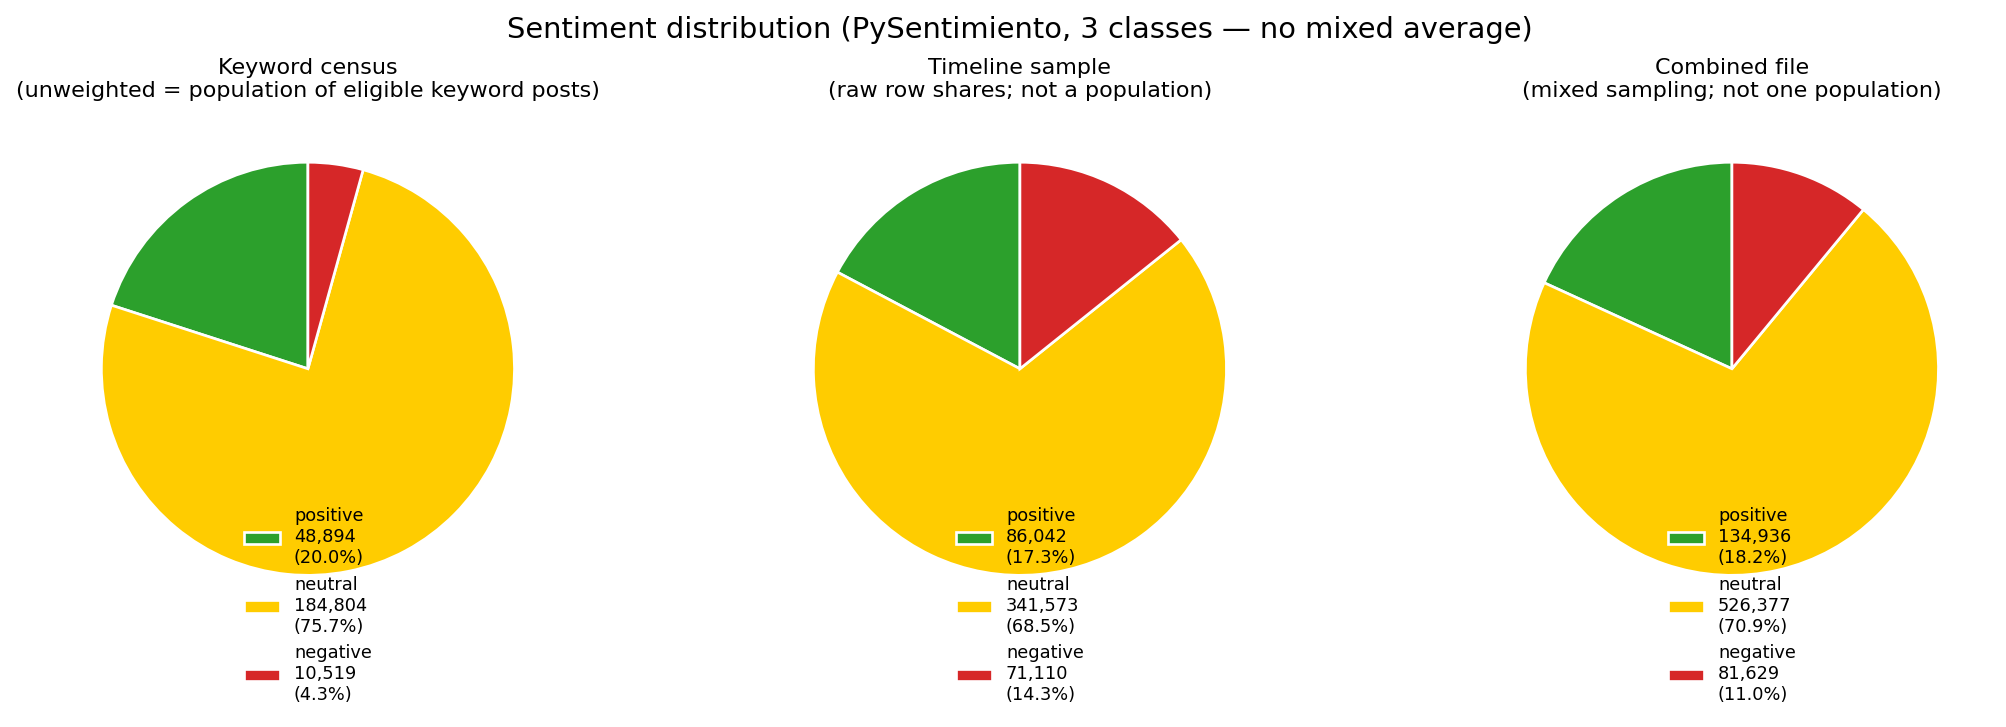

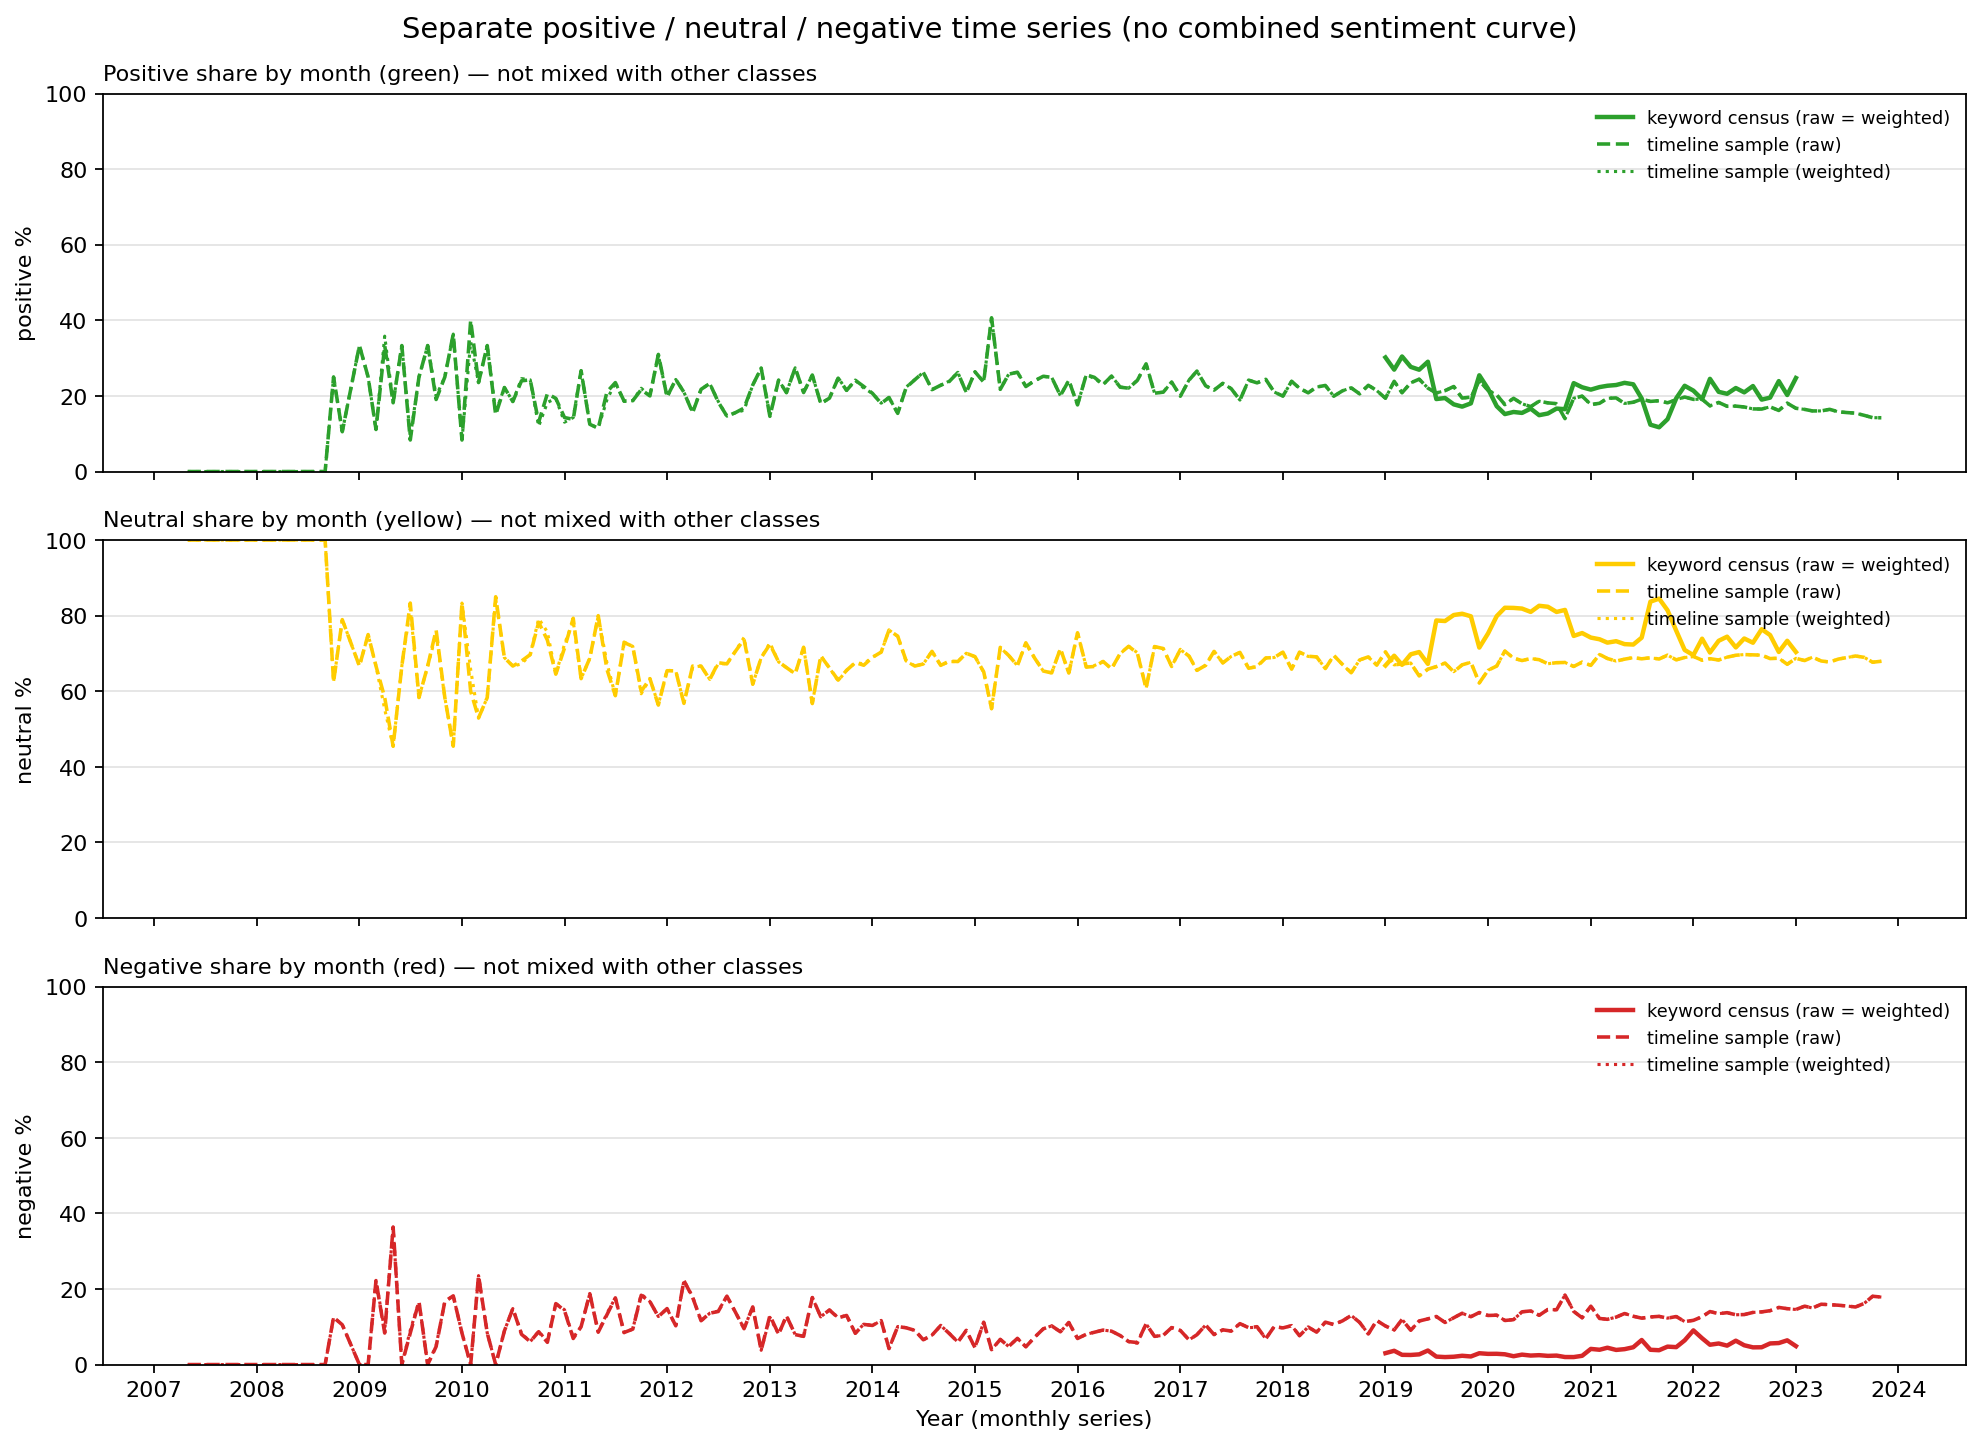

In [2]:
dist = pd.read_csv(OUT / "sentiment_distribution.csv", encoding="utf-8-sig")
print("sentiment_distribution rows", len(dist))
display(dist)
users = pd.read_csv(OUT / "user_sentiment_summary.csv", encoding="utf-8-sig")
print("scored users", len(users))
assert len(users) == 35250
display(users.sort_values("n_posts", ascending=False).head(8))
display(Image(filename=str(OUT / "sentiment_distribution.png")))
display(Image(filename=str(OUT / "sentiment_over_time_monthly.png")))
print("DONE sentiment verification")
